In [139]:
import numpy as np
import torch 
import torch.nn as nn
import torch.optim as optim
from torchsummary import summary
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

In [140]:
data = load_iris()
data

{'data': array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
  

In [141]:
X_train, X_test, y_train, y_test = train_test_split(
    data.data, 
    data.target,
    test_size = 0.4
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_test, 
    y_test,
    test_size=0.5
)

In [142]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)

StandardScaler()

In [143]:
X_train = scaler.transform(X_train)
X_valid = scaler.transform(X_valid)
X_test = scaler.transform(X_test)

In [144]:
X_train = torch.tensor(X_train, dtype = torch.float32)
y_train = torch.tensor(y_train)
X_valid = torch.tensor(X_valid, dtype = torch.float32)
y_valid = torch.tensor(y_valid)
X_test = torch.tensor(X_test, dtype = torch.float32)
y_test = torch.tensor(y_test)

In [145]:
X_train.shape

torch.Size([90, 4])

In [146]:
model_classifier = nn.Sequential(
    nn.Linear(4, 8),
    nn.Linear(8, 8),
    nn.ReLU(),
    nn.Linear(8, 3)
)
loss_fn = nn.CrossEntropyLoss()

In [147]:
lr = 0.01
momentum = 0.9
optimizer = optim.SGD(
    model_classifier.parameters(),
    lr = lr,
    momentum=momentum,
    nesterov=True
)

In [148]:
def evaluate(model_classifier, X_valid, y_valid):
    with torch.no_grad():
        y_pred = model_classifier(X_valid)
    y_pred = torch.argmax(y_pred, dim = 1)
    return sum(y_pred == y_valid) / len(y_valid)

In [149]:
num_epochs = 50
losses = []
for epoch in range(num_epochs):
    epoch_loss = []
    for x_train, y_t in zip(X_train, y_train):
        y_pred = model_classifier(x_train)
        loss = loss_fn(y_pred, y_t)
        epoch_loss.append(loss.item())

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    avg_loss = sum(epoch_loss) / len(epoch_loss)
    losses.append(avg_loss)
    acc = evaluate(model_classifier, X_valid, y_valid)
    print(f'{avg_loss} -- {acc}')

0.8090483835329199 -- 0.8666666746139526
0.48290700486314664 -- 0.9666666388511658
0.3481104757614048 -- 0.9666666388511658
0.21587115452225084 -- 0.9666666388511658
0.17623998095524357 -- 0.9666666388511658
0.18464876401178318 -- 0.9666666388511658
0.17095349588610892 -- 0.9666666388511658
0.15154236986276778 -- 0.9666666388511658
0.13804516644577233 -- 0.9666666388511658
0.1251121897099842 -- 0.9666666388511658
0.11891065710413184 -- 0.9333333373069763
0.10404424041051041 -- 0.9333333373069763
0.10019312292889077 -- 0.9666666388511658
0.14919314417007729 -- 0.9666666388511658
0.10219227700610974 -- 0.9666666388511658
0.09650373162284673 -- 0.9333333373069763
0.09276861794438042 -- 0.9333333373069763
0.09334726247433942 -- 0.9333333373069763
0.08807348428567821 -- 0.9333333373069763
0.1382156593687038 -- 0.9666666388511658
0.092183734966117 -- 0.9666666388511658
0.10079226998764676 -- 0.9333333373069763
0.07889912053588988 -- 0.9666666388511658
0.14023418693895387 -- 0.966666638851165

In [150]:
with torch.no_grad():
    y_pred = model_classifier(X_test)
y_pred = torch.argmax(y_pred, dim = 1)
print(sum(y_pred == y_test) / len(y_test))

tensor(1.)


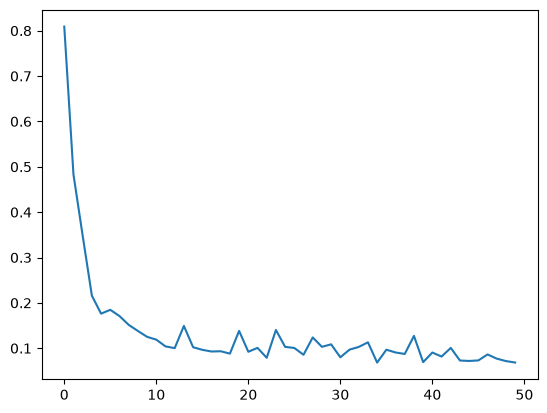

In [151]:
import matplotlib.pyplot as plt
plt.plot(losses)
plt.show()